In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
DATA_FILE = Path("data/superstore_2019.xlsx")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_FILE}. Run this notebook from the project root."
    )
df = pd.read_excel(DATA_FILE, engine="openpyxl")


In [3]:
df.shape

(9994, 21)

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2016-110422,2016-01-21,2016-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,Florida,33180.0,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2019-121258,2019-02-26,2019-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2019-121258,2019-02-26,2019-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2019-121258,2019-02-26,2019-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2019-119914,2019-05-04,2019-05-09,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,California,92683.0,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9994 non-null   int64         
 1   Order ID        9994 non-null   object        
 2   Order Date      9994 non-null   datetime64[ns]
 3   Ship Date       9994 non-null   datetime64[ns]
 4   Ship Mode       9994 non-null   object        
 5   Customer ID     9994 non-null   object        
 6   Customer Name   9994 non-null   object        
 7   Segment         9994 non-null   object        
 8   Country/Region  9994 non-null   object        
 9   City            9994 non-null   object        
 10  State           9994 non-null   object        
 11  Postal Code     9983 non-null   float64       
 12  Region          9994 non-null   object        
 13  Product ID      9994 non-null   object        
 14  Category        9994 non-null   object        
 15  Sub-

In [7]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2018-04-30 10:03:51.979187712,2018-05-04 09:03:29.645787392,55245.233297,229.858001,3.789574,0.156203,28.656896
min,1.000000,2016-01-03 00:00:00,2016-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2017-05-23 00:00:00,2017-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2018-06-26 00:00:00,2018-06-29 00:00:00,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2019-05-14 00:00:00,2019-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2019-12-30 00:00:00,2020-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32038.715955,623.245101,2.225110,0.206452,234.260108


In [8]:
df.isna().sum()

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State              0
Postal Code       11
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount           0
Profit             0
dtype: int64

In [9]:
missing = df.isna().sum().sort_values(ascending=False)

missing_pct = (missing / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing": missing,
    "Percentage": missing_pct
})

missing_summary

,Missing,Percentage
Postal Code,11,0.11
Order ID,0,0.00
Order Date,0,0.00
Ship Date,0,0.00
Row ID,0,0.00
Ship Mode,0,0.00
Customer ID,0,0.00
Segment,0,0.00
Customer Name,0,0.00
Country/Region,0,0.00


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

Row ID                     int64
Order ID                  object
Order Date        datetime64[ns]
Ship Date         datetime64[ns]
Ship Mode                 object
Customer ID               object
Customer Name             object
Segment                   object
Country/Region            object
City                      object
State                     object
Postal Code              float64
Region                    object
Product ID                object
Category                  object
Sub-Category              object
Product Name              object
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object

In [12]:
df_clean = df.copy()

# Postal Code is an identifier rather than a numeric measure.
# Keep missing source values explicit instead of guessing a ZIP code.
df_clean["Postal Code"] = (
    df_clean["Postal Code"]
    .astype("Int64")
    .astype("string")
    .str.zfill(5)
    .fillna("Unknown")
)

In [13]:
df_clean.isna().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State             0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [14]:
numeric_cols = ["Sales", "Quantity", "Discount", "Profit"]

df_clean[numeric_cols].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [15]:
print("Sales <= 0:", (df_clean["Sales"] <= 0).sum())
print("Quantity <= 0:", (df_clean["Quantity"] <= 0).sum())
print("Discount < 0:", (df_clean["Discount"] < 0).sum())
print("Discount > 1:", (df_clean["Discount"] > 1).sum())

Sales <= 0: 0
Quantity <= 0: 0
Discount < 0: 0
Discount > 1: 0


In [16]:
print("Invalid Order Dates:", df_clean["Order Date"].isna().sum())
print("Invalid Ship Dates:", df_clean["Ship Date"].isna().sum())

Invalid Order Dates: 0
Invalid Ship Dates: 0


In [17]:
print(
    "Ship Date before Order Date:",
    (df_clean["Ship Date"] < df_clean["Order Date"]).sum()
)

Ship Date before Order Date: 0


In [18]:
df_clean["Profit Margin"] = np.where(
    df_clean["Sales"].ne(0),
    df_clean["Profit"] / df_clean["Sales"],
    np.nan
)

df_clean["Shipping Duration"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
).dt.days

q1 = df_clean["Sales"].quantile(0.25)
q3 = df_clean["Sales"].quantile(0.75)

df_clean["Sales Performance Category"] = pd.cut(
    df_clean["Sales"],
    bins=[-np.inf, q1, q3, np.inf],
    labels=["Low", "Medium", "High"]
)

In [19]:
df_clean

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin,Shipping Duration,Sales Performance Category
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,0.1600,3,High
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,0.3000,3,High
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,0.4700,4,Low
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-0.4000,7,High
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,0.1125,7,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2016-110422,2016-01-21,2016-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,Florida,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028,0.1625,2,Medium
9990,9991,CA-2019-121258,2019-02-26,2019-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332,0.1700,5,Medium
9991,9992,CA-2019-121258,2019-02-26,2019-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932,0.0750,5,High
9992,9993,CA-2019-121258,2019-02-26,2019-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200,0.4500,5,Medium


## Reusable Preprocessing Functions

In [20]:
def check_missing_values(data):
    missing = data.isna().sum()
    pct = (missing / len(data) * 100).round(2)
    result = pd.DataFrame({"Missing Values": missing, "Missing Percentage": pct})
    return result[result["Missing Values"] > 0]

def check_duplicates(data):
    return data.duplicated().sum()

def validate_data(data):
    return pd.Series({
        "Invalid Sales": (data["Sales"] <= 0).sum(),
        "Invalid Quantity": (data["Quantity"] <= 0).sum(),
        "Invalid Discount": ((data["Discount"] < 0) | (data["Discount"] > 1)).sum(),
        "Ship Date Before Order Date": (data["Ship Date"] < data["Order Date"]).sum()
    })

def detect_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = data[(data[column] < lower) | (data[column] > upper)]
    return outliers, lower, upper

In [21]:
display(check_missing_values(df_clean))
print("Duplicate rows:", check_duplicates(df_clean))
display(validate_data(df_clean))

,Missing Values,Missing Percentage


Duplicate rows: 0


Invalid Sales                  0
Invalid Quantity               0
Invalid Discount               0
Ship Date Before Order Date    0
dtype: int64

## Outlier Analysis

In [22]:
outliers, lower_bound, upper_bound = detect_outliers(df_clean, "Sales")
df_clean["is_sales_outlier"] = (
    (df_clean["Sales"] < lower_bound) | (df_clean["Sales"] > upper_bound)
)
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Sales outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df_clean) * 100, 2), "%")

Lower bound: -271.71
Upper bound: 498.93
Sales outliers: 1167
Outlier percentage: 11.68 %


## Advanced EDA - Sales

In [23]:
sales_by_category = df_clean.groupby("Category")["Sales"].sum().sort_values(ascending=False)
sales_by_region = df_clean.groupby("Region")["Sales"].sum().sort_values(ascending=False)
sales_by_segment = df_clean.groupby("Segment")["Sales"].sum().sort_values(ascending=False)

display(sales_by_category)
display(sales_by_region)
display(sales_by_segment)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64

## Profitability Analysis

In [24]:
profit_by_category = df_clean.groupby("Category")["Profit"].sum().sort_values(ascending=False)
profit_by_region = df_clean.groupby("Region")["Profit"].sum().sort_values(ascending=False)

display(profit_by_category)
display(profit_by_region)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64

## Customer and Product Analysis

In [25]:
top_customers = df_clean.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10)
top_products = df_clean.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)

display(top_customers)
display(top_products)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

## Operational Analysis

In [26]:
shipping_by_mode = df_clean.groupby("Ship Mode")["Shipping Duration"].mean().sort_values()
shipping_by_region = df_clean.groupby("Region")["Shipping Duration"].mean().sort_values()

display(shipping_by_mode)
display(shipping_by_region)

Ship Mode
Same Day          0.044199
First Class       2.182705
Second Class      3.237532
Standard Class    5.006535
Name: Shipping Duration, dtype: float64

Region
East       3.908357
West       3.930378
South      3.958025
Central    4.057254
Name: Shipping Duration, dtype: float64

## Statistical Analysis

In [27]:
analysis_cols = [
    "Sales", "Quantity", "Discount", "Profit",
    "Profit Margin", "Shipping Duration"
]

display(df_clean[analysis_cols].describe())
correlation = df_clean[analysis_cols].corr()
display(correlation)

,Sales,Quantity,Discount,Profit,Profit Margin,Shipping Duration
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896,0.120314,3.958075
std,623.245101,2.225110,0.206452,234.260108,0.466754,1.747937
min,0.444000,1.000000,0.000000,-6599.978000,-2.750000,0.000000
25%,17.280000,2.000000,0.000000,1.728750,0.075000,3.000000
50%,54.490000,3.000000,0.200000,8.666500,0.270000,4.000000
75%,209.940000,5.000000,0.200000,29.364000,0.362500,5.000000
max,22638.480000,14.000000,0.800000,8399.976000,0.500000,7.000000


,Sales,Quantity,Discount,Profit,Profit Margin,Shipping Duration
Sales,1.000000,0.200795,-0.028190,0.479064,0.003444,-0.007350
Quantity,0.200795,1.000000,0.008623,0.066253,-0.005280,0.018315
Discount,-0.028190,0.008623,1.000000,-0.219487,-0.864452,0.000452
Profit,0.479064,0.066253,-0.219487,1.000000,0.223732,-0.004658
Profit Margin,0.003444,-0.005280,-0.864452,0.223732,1.000000,-0.011800
Shipping Duration,-0.007350,0.018315,0.000452,-0.004658,-0.011800,1.000000


## Trend Analysis

In [28]:
# Extract Year and Month from Order Date
df_clean["Year"] = df_clean["Order Date"].dt.year
df_clean["Month"] = df_clean["Order Date"].dt.month

# Calculate monthly sales
monthly_sales = (
    df_clean.groupby(["Year", "Month"])["Sales"]
    .sum()
    .reset_index()
)

# Create a Year-Month column
monthly_sales["Year-Month"] = (
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str).str.zfill(2)
)

display(monthly_sales)

,Year,Month,Sales,Year-Month
0,2016,1,14236.8950,2016-01
1,2016,2,4519.8920,2016-02
2,2016,3,55691.0090,2016-03
3,2016,4,28295.3450,2016-04
4,2016,5,23648.2870,2016-05
5,2016,6,34595.1276,2016-06
6,2016,7,33946.3930,2016-07
7,2016,8,27909.4685,2016-08
8,2016,9,81777.3508,2016-09
9,2016,10,31453.3930,2016-10


## Visualizations

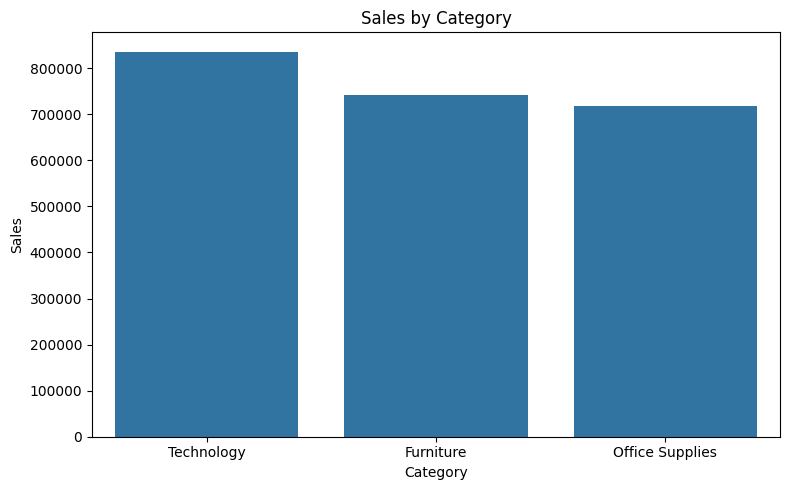

In [29]:
plt.figure(figsize=(8, 5))
sns.barplot(x=sales_by_category.index, y=sales_by_category.values, color=sns.color_palette()[0])
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

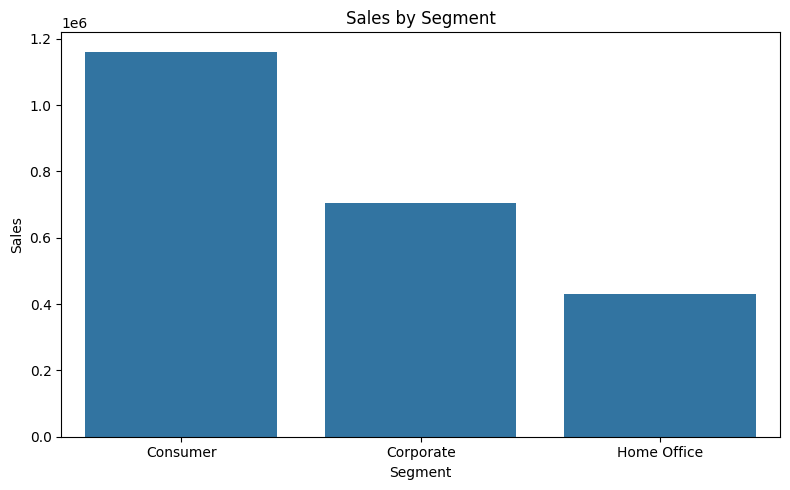

In [30]:
plt.figure(figsize=(8, 5))
sns.barplot(x=sales_by_segment.index, y=sales_by_segment.values, color=sns.color_palette()[0])
plt.title("Sales by Segment")
plt.xlabel("Segment")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

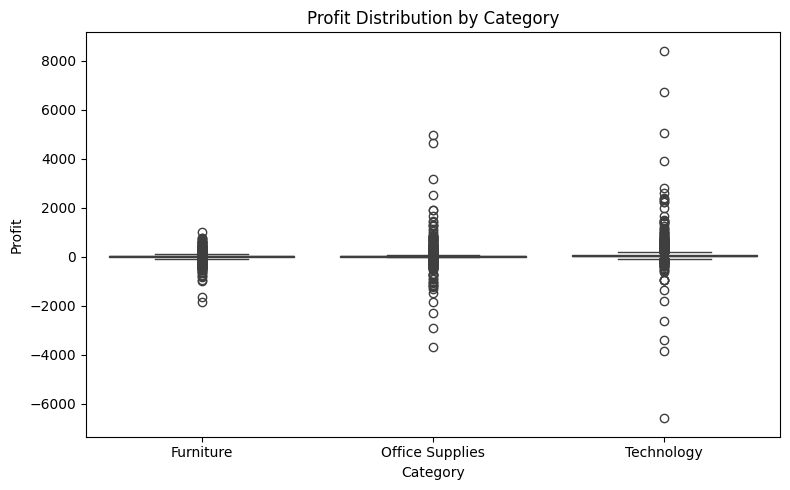

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Category", y="Profit")
plt.title("Profit Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


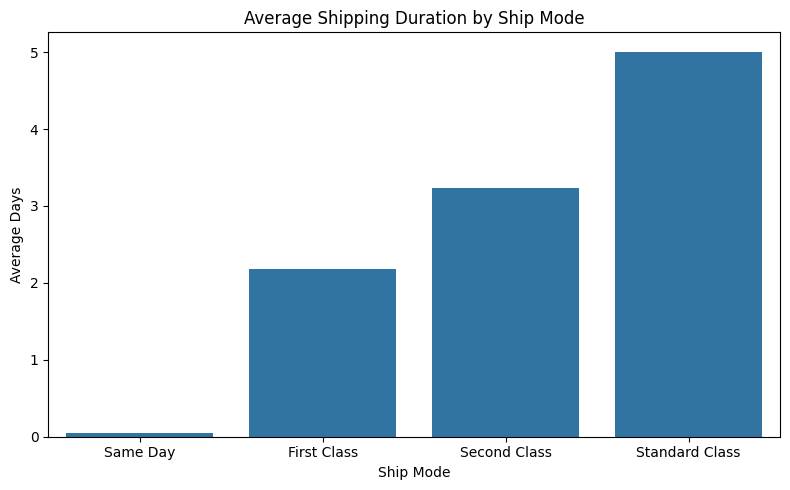

In [32]:
plt.figure(figsize=(8, 5))
sns.barplot(x=shipping_by_mode.index, y=shipping_by_mode.values, color=sns.color_palette()[0])
plt.title("Average Shipping Duration by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Days")
plt.tight_layout()
plt.show()

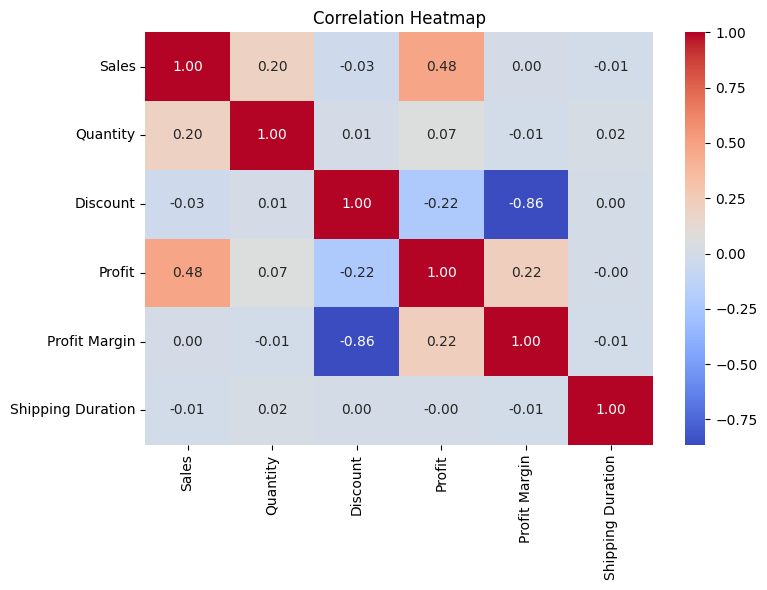

In [33]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


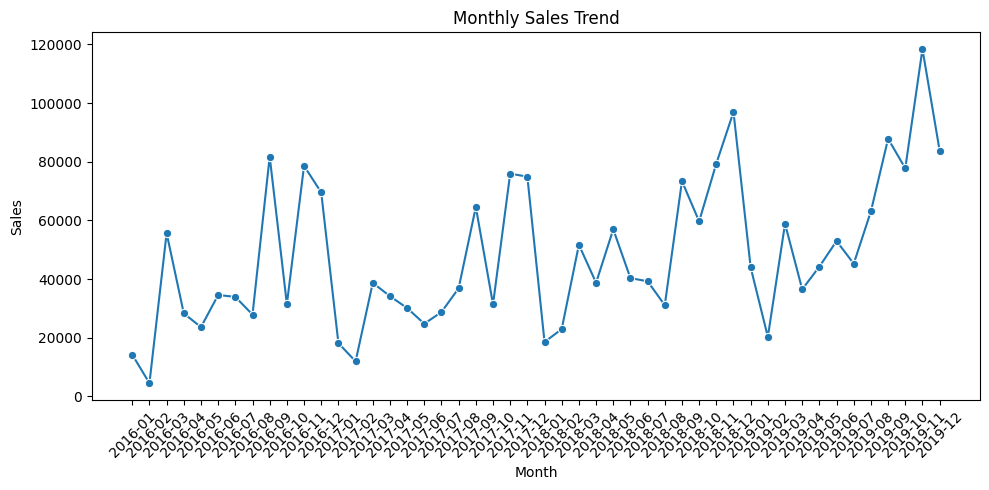

In [34]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x="Year-Month", y="Sales", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Automated KPI Summary

In [35]:
def create_kpi_summary(data):
    return pd.Series({
        "Total Sales": data["Sales"].sum(),
        "Total Profit": data["Profit"].sum(),
        "Average Sales": data["Sales"].mean(),
        "Total Quantity": data["Quantity"].sum(),
        "Total Orders": data["Order ID"].nunique(),
        "Total Customers": data["Customer ID"].nunique(),
        "Average Shipping Duration": data["Shipping Duration"].mean(),
        "Overall Profit Margin": data["Profit"].sum() / data["Sales"].sum()
    })

kpi_summary = create_kpi_summary(df_clean)
display(kpi_summary)

Total Sales                  2.297201e+06
Total Profit                 2.863970e+05
Average Sales                2.298580e+02
Total Quantity               3.787300e+04
Total Orders                 5.009000e+03
Total Customers              7.930000e+02
Average Shipping Duration    3.958075e+00
Overall Profit Margin        1.246722e-01
dtype: float64

## Key Findings & Business Recommendations

- **Technology** generates the highest sales and profit, with a much stronger profit margin than Furniture.
- **Furniture** produces substantial sales but comparatively low profit, so pricing, discounting, and product-level profitability should be reviewed.
- **West** is the strongest region by both sales and profit, while other regions can be compared against its performance drivers.
- **Consumer** is the largest customer segment by sales and should remain a key commercial focus.
- The correlation analysis shows a strong negative relationship between **Discount** and **Profit Margin**, so high-discount transactions should be reviewed carefully.
- Monthly sales show noticeable seasonality, with stronger periods toward the end of the year; inventory and campaigns can be planned around these peaks.

## Export Cleaned Data and Visual Reports

In [36]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export cleaned data and key analytical tables.
df_clean.to_csv(OUTPUT_DIR / "cleaned_superstore.csv", index=False)
kpi_summary.to_csv(OUTPUT_DIR / "kpi_summary.csv", header=["Value"])
sales_by_category.to_csv(OUTPUT_DIR / "sales_by_category.csv", header=["Sales"])
profit_by_category.to_csv(OUTPUT_DIR / "profit_by_category.csv", header=["Profit"])
sales_by_region.to_csv(OUTPUT_DIR / "sales_by_region.csv", header=["Sales"])
profit_by_region.to_csv(OUTPUT_DIR / "profit_by_region.csv", header=["Profit"])
sales_by_segment.to_csv(OUTPUT_DIR / "sales_by_segment.csv", header=["Sales"])
shipping_by_mode.to_csv(OUTPUT_DIR / "average_shipping_duration_by_mode.csv", header=["Average Shipping Days"])
monthly_sales.to_csv(OUTPUT_DIR / "monthly_sales.csv", index=False)
top_customers.to_csv(OUTPUT_DIR / "top_10_customers_by_sales.csv", header=["Sales"])
top_products.to_csv(OUTPUT_DIR / "top_10_products_by_sales.csv", header=["Sales"])
correlation.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

# Export all portfolio charts at presentation-friendly resolution.
def save_bar_chart(series, title, xlabel, ylabel, filename, figsize=(9, 5)):
    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(x=series.index.astype(str), y=series.values, ax=ax,
                color=sns.color_palette("deep")[0])
    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=250, bbox_inches="tight")
    plt.close(fig)

save_bar_chart(sales_by_category, "Total Sales by Category", "Category", "Sales", "sales_by_category.png")
save_bar_chart(profit_by_category, "Total Profit by Category", "Category", "Profit", "profit_by_category.png")
save_bar_chart(sales_by_region, "Total Sales by Region", "Region", "Sales", "sales_by_region.png")
save_bar_chart(sales_by_segment, "Total Sales by Customer Segment", "Segment", "Sales", "sales_by_segment.png")
save_bar_chart(shipping_by_mode, "Average Shipping Duration by Ship Mode", "Ship Mode", "Average Days", "average_shipping_duration_by_mode.png")

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Category", y="Profit", ax=ax)
ax.set_title("Profit Distribution by Category", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Category")
ax.set_ylabel("Profit")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "profit_distribution_by_category.png", dpi=250, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.4, ax=ax)
ax.set_title("Correlation Heatmap", fontsize=14, fontweight="bold", pad=12)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=250, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly_sales, x="Year-Month", y="Sales", marker="o", ax=ax)
ax.set_title("Monthly Sales Trend", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Year-Month")
ax.set_ylabel("Sales")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "monthly_sales_trend.png", dpi=250, bbox_inches="tight")
plt.close(fig)

print(f"Export completed successfully: {OUTPUT_DIR.resolve()}")
print(f"Rows exported: {len(df_clean):,}")
print(f"Charts exported: {len(list(OUTPUT_DIR.glob('*.png')))}")


Export completed successfully: /mnt/data/superstore_sales_analysis/outputs
Rows exported: 9,994
Charts exported: 8


## Memory Optimization

In [37]:
print("Memory before optimization:",
      round(df_clean.memory_usage(deep=True).sum() / 1024**2, 2), "MB")

category_cols = [
    "Ship Mode", "Segment", "Country", "City",
    "State", "Region", "Category", "Sub-Category"
]

for col in category_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype("category")

print("Memory after optimization:",
      round(df_clean.memory_usage(deep=True).sum() / 1024**2, 2), "MB")

Memory before optimization: 8.96 MB
Memory after optimization: 5.2 MB
